# Did the ad campaign work? — A/B test analysis

**Business question.** A company ran a campaign in which most users were shown a product **advertisement** (test group, `ad`),
while a small hold-out group saw a **public-service announcement** in the same slot (control group, `psa`).
Did the ad cause more people to buy, and by how much?

**Dataset.** [Marketing A/B Testing](https://www.kaggle.com/datasets/faviovaz/marketing-ab-testing) — 588,101 users.

| Chapter | |
|---|---|
| 1 | Experiment framing |
| 2 | Data quality & Sample Ratio Mismatch |
| 3 | Exploratory analysis |
| 4 | Significance testing (frequentist) |
| 5 | Robustness: bootstrap, Bayesian, power |
| 6 | Segments & multiple testing |
| 7 | Decision & business impact |

In [1]:
import json, sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.multitest import multipletests

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from ab_stats import srm_check, ztest_props, bootstrap_lift, bayes_ab, power_mde, required_sample_size

FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
SITE_DATA = ROOT / "docs" / "data"; SITE_DATA.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", font_scale=1.05)
PALETTE = {"psa": "#9aa5b1", "ad": "#2f6fdb"}
ALPHA = 0.05

## 1. Experiment framing

| | |
|---|---|
| **Unit** | user |
| **Control** | `psa` — public-service announcement |
| **Treatment** | `ad` — product advertisement |
| **Primary metric** | conversion rate = purchasers / users |
| **H₀** | p_ad = p_psa |
| **H₁** | p_ad ≠ p_psa (two-sided — we also want to know if the ad *hurt*) |
| **α** | 0.05 |

**Guardrails.** In a real company we would also watch metrics that must *not* get worse
(e.g. unsubscribe rate, complaint rate). This dataset has none, which is noted as a limitation.

In [2]:
df = pd.read_csv(ROOT / "data" / "marketing_AB.csv", index_col=0)
df.columns = [c.strip().replace(" ", "_") for c in df.columns]
df.head()

,user_id,test_group,converted,total_ads,most_ads_day,most_ads_hour
0,1069124,ad,False,130,Monday,20
1,1119715,ad,False,93,Tuesday,22
2,1144181,ad,False,21,Tuesday,18
3,1435133,ad,False,355,Tuesday,10
4,1015700,ad,False,276,Friday,14


## 2. Data quality checks

In [3]:
checks = {
    "rows": len(df),
    "missing values": int(df.isna().sum().sum()),
    "duplicate user ids": int(df["user_id"].duplicated().sum()),
    "users in both groups": int(df.groupby("user_id")["test_group"].nunique().gt(1).sum()),
    "groups": sorted(df["test_group"].unique()),
}
checks

{'rows': 588101,
 'missing values': 0,
 'duplicate user ids': 0,
 'users in both groups': 0,
 'groups': ['ad', 'psa']}

### Sample Ratio Mismatch (SRM)

The groups are deliberately unequal: about **96% ad / 4% PSA**. That is a design choice, since the
company wants to reach as many people as possible with the ad. But we must check that the observed split matches the
**intended** one. If it doesn't, something in the assignment is broken (bots, logging bugs, redirect errors) and *no*
result can be trusted.

The intended split isn't documented, so we assume a **4% hold-out**, which is standard for this kind of campaign.

In [4]:
n = df["test_group"].value_counts()
srm = srm_check(n_control=n["psa"], n_test=n["ad"], expected_control_share=0.04)
print(f"observed control share: {n['psa'] / n.sum():.4%}")
print(f"chi2 = {srm.chi2:.2f}, p = {srm.p_value:.3g} → SRM detected: {srm.mismatch}")

observed control share: 4.0000%
chi2 = 0.00, p = 1 → SRM detected: False


The control share is **exactly 4.00%**, which strongly suggests the dataset was sampled to a fixed ratio by design.
**Honest caveat:** because the expected share was inferred from the data, this check can't fail here. In a real
experiment, take the expected ratio from the experiment configuration *before* looking at the data. Then the
same function becomes a real safeguard (see `tests/test_ab_stats.py`, where it catches a 55/45 split meant to be 50/50).

## 3. Exploratory analysis

In [5]:
summary = (df.groupby("test_group")["converted"]
             .agg(users="count", conversions="sum", rate="mean")
             .loc[["psa", "ad"]])
summary["rate_%"] = (summary["rate"] * 100).round(3)
summary

,users,conversions,rate,rate_%
test_group,,,,
psa,23524,420,0.017854,1.785
ad,564577,14423,0.025547,2.555


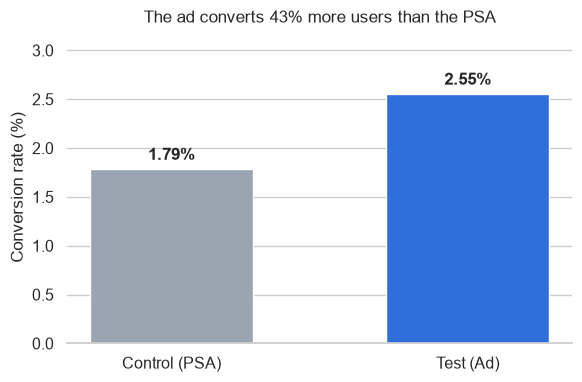

In [6]:
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(["Control (PSA)", "Test (Ad)"], summary["rate"] * 100,
              color=[PALETTE["psa"], PALETTE["ad"]], width=0.55)
ax.bar_label(bars, fmt="%.2f%%", padding=4, fontweight="bold")
ax.set_ylabel("Conversion rate (%)"); ax.set_ylim(0, 3.2); ax.grid(axis="x", visible=False)
ax.set_title("The ad converts 43% more users than the PSA")
sns.despine(left=True); plt.tight_layout(); plt.savefig(FIG / "conversion_by_group.png", dpi=200)
plt.show()

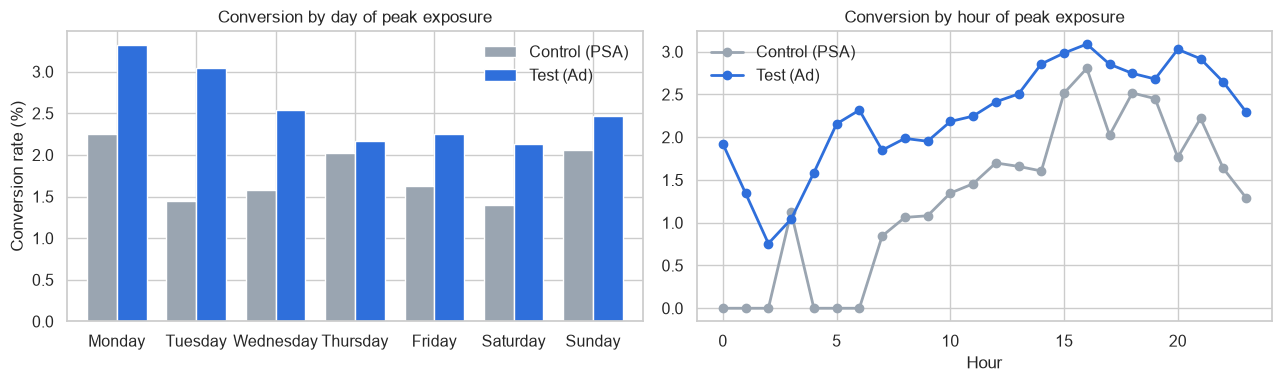

In [7]:
DAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
by_day = (df.groupby(["most_ads_day", "test_group"])["converted"].mean()
            .unstack().reindex(DAYS)[["psa", "ad"]])
by_hour = df.groupby(["most_ads_hour", "test_group"])["converted"].mean().unstack()[["psa", "ad"]]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
(by_day * 100).plot(kind="bar", ax=axes[0], color=PALETTE.values(), width=0.75)
axes[0].set(title="Conversion by day of peak exposure", xlabel="", ylabel="Conversion rate (%)")
axes[0].tick_params(axis="x", rotation=0)
(by_hour * 100).plot(ax=axes[1], color=PALETTE.values(), marker="o", lw=2)
axes[1].set(title="Conversion by hour of peak exposure", xlabel="Hour", ylabel="")
for a in axes: a.legend(["Control (PSA)", "Test (Ad)"], frameon=False)
plt.tight_layout(); plt.savefig(FIG / "conversion_by_day_hour.png", dpi=200); plt.show()

**Exposure (dose–response).** Users who saw more ads converted more, and this holds in *both* groups.
`total_ads` is measured **after** assignment, so this is a correlation, not a causal effect:
heavy users of the platform see more ads *and* are more likely to buy. The fair comparison is the
gap **between** the groups inside each exposure bucket.

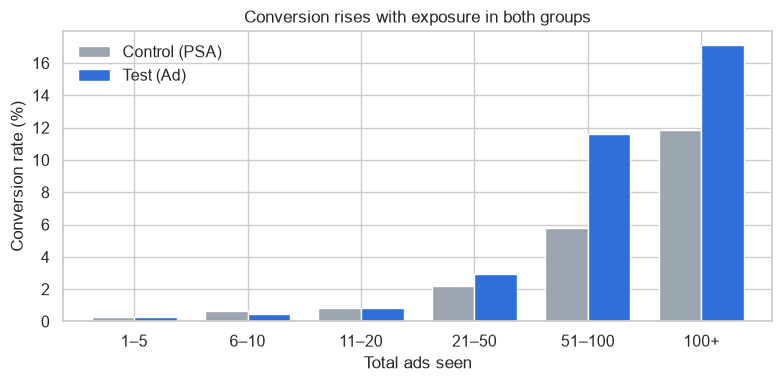

,psa,ad,users
ads_bucket,,,
1–5,0.28,0.25,177823
6–10,0.67,0.49,82952
11–20,0.82,0.84,127484
21–50,2.18,2.92,130776
51–100,5.77,11.63,46002
100+,11.88,17.14,23064


In [8]:
bins = [0, 5, 10, 20, 50, 100, np.inf]
labels = ["1–5", "6–10", "11–20", "21–50", "51–100", "100+"]
df["ads_bucket"] = pd.cut(df["total_ads"], bins=bins, labels=labels)
by_exposure = df.groupby(["ads_bucket", "test_group"], observed=True)["converted"].mean().unstack()[["psa", "ad"]]
exposure_n = df.groupby("ads_bucket", observed=True).size()

fig, ax = plt.subplots(figsize=(8, 4))
(by_exposure * 100).plot(kind="bar", ax=ax, color=PALETTE.values(), width=0.75)
ax.set(title="Conversion rises with exposure in both groups", xlabel="Total ads seen", ylabel="Conversion rate (%)")
ax.tick_params(axis="x", rotation=0); ax.legend(["Control (PSA)", "Test (Ad)"], frameon=False)
plt.tight_layout(); plt.savefig(FIG / "conversion_by_exposure.png", dpi=200); plt.show()
pd.concat([(by_exposure * 100).round(2), exposure_n.rename("users")], axis=1)

**Finding: the ad needs repetition.** Among users who saw 1–10 ads, the ad group converts no better than the PSA group
(in fact slightly worse). The gap opens above about 20 ads and is largest at 51–100 ads (11.6% vs 5.8%).
This is descriptive, not causal, but it raises a useful question for the marketing team: **frequency matters**,
and a follow-up experiment that randomises *how many* ads people see could find the best frequency.

## 4. Significance testing

In [9]:
c, t = summary.loc["psa"], summary.loc["ad"]
z = ztest_props(int(c.conversions), int(c.users), int(t.conversions), int(t.users))

chi2, p_chi, *_ = stats.chi2_contingency(pd.crosstab(df["test_group"], df["converted"]), correction=False)

print(f"Control rate     : {z.rate_control:.4%}")
print(f"Test rate        : {z.rate_test:.4%}")
print(f"Absolute uplift  : {z.abs_diff * 100:+.3f} pp  (95% CI {z.ci_low * 100:.3f} to {z.ci_high * 100:.3f} pp)")
print(f"Relative lift    : {z.rel_lift:+.1%}")
print(f"z = {z.z:.2f}, p = {z.p_value:.2e}")
print(f"chi-square check : chi2 = {chi2:.2f} (= z² = {z.z**2:.2f}), p = {p_chi:.2e}")

Control rate     : 1.7854%
Test rate        : 2.5547%
Absolute uplift  : +0.769 pp  (95% CI 0.595 to 0.943 pp)
Relative lift    : +43.1%
z = 7.37, p = 1.71e-13
chi-square check : chi2 = 54.32 (= z² = 54.32), p = 1.71e-13


**Reading the result.** p is far below 0.05, so we reject H₀. The 95% confidence interval for the uplift
does not include 0: we are confident the ad raises conversion by somewhere between **≈0.6 and ≈0.9 percentage points**.

The chi-square test gives an identical p-value, as it should: for a 2×2 table, χ² = z².

## 5. Robustness

### 5a. Bootstrap

The z-test relies on a normal approximation. With only 420 conversions in the control group, it's worth checking it
against a method that makes no such assumption.

Bootstrap relative lift: +43.1%  (95% CI +30.6% to +57.9%)


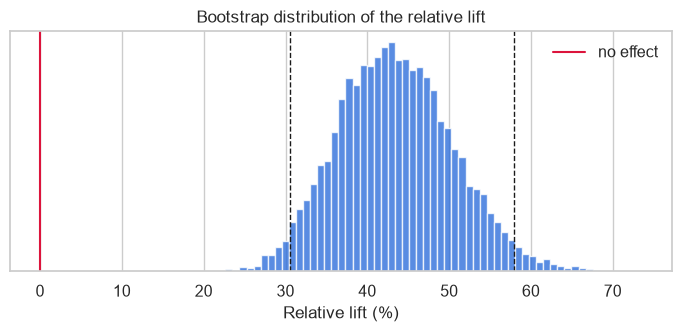

In [10]:
y_c = df.loc[df.test_group == "psa", "converted"].to_numpy()
y_t = df.loc[df.test_group == "ad", "converted"].to_numpy()
boot = bootstrap_lift(y_c, y_t, n_boot=10_000)
print(f"Bootstrap relative lift: {boot['lift']:+.1%}  (95% CI {boot['ci_low']:+.1%} to {boot['ci_high']:+.1%})")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(boot["samples"] * 100, bins=60, color=PALETTE["ad"], alpha=0.8)
for v in (boot["ci_low"], boot["ci_high"]): ax.axvline(v * 100, ls="--", c="k", lw=1)
ax.axvline(0, c="crimson", lw=1.5, label="no effect")
ax.set(title="Bootstrap distribution of the relative lift", xlabel="Relative lift (%)", yticks=[])
ax.legend(frameon=False); plt.tight_layout(); plt.savefig(FIG / "bootstrap_lift.png", dpi=200); plt.show()

### 5b. Bayesian view

Stakeholders rarely ask "what is the p-value?". They ask *"how sure are we the ad is better?"*
A Beta-Binomial model answers that directly. We use a flat Beta(1, 1) prior, so the data does all the talking.

P(ad beats PSA)  : 100.0000%
Expected lift    : +43.1%  (95% credible interval +29.9% to +57.5%)


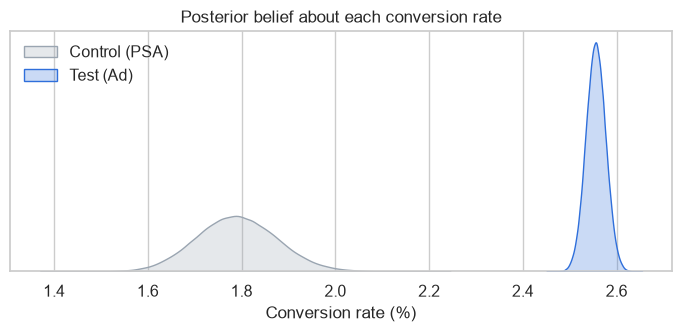

In [11]:
bayes = bayes_ab(int(c.conversions), int(c.users), int(t.conversions), int(t.users))
print(f"P(ad beats PSA)  : {bayes['prob_test_better']:.4%}")
print(f"Expected lift    : {bayes['expected_lift']:+.1%}  (95% credible interval "
      f"{bayes['lift_ci'][0]:+.1%} to {bayes['lift_ci'][1]:+.1%})")

fig, ax = plt.subplots(figsize=(7, 3.5))
for key, name in [("post_control", "psa"), ("post_test", "ad")]:
    sns.kdeplot(bayes[key] * 100, ax=ax, fill=True, color=PALETTE[name], label={"psa": "Control (PSA)", "ad": "Test (Ad)"}[name])
ax.set(title="Posterior belief about each conversion rate", xlabel="Conversion rate (%)", yticks=[], ylabel="")
ax.legend(frameon=False); plt.tight_layout(); plt.savefig(FIG / "bayesian_posteriors.png", dpi=200); plt.show()

### 5c. Power & minimum detectable effect

Was the experiment big enough? With an unequal split, the **small control group limits power**.

In [12]:
mde = power_mde(z.rate_control, int(c.users), int(t.users))
n_bal = required_sample_size(z.rate_control, mde)
print(f"Minimum detectable uplift with this design (80% power): {mde * 100:.3f} pp  ({mde / z.rate_control:.1%} relative)")
print(f"Observed uplift: {z.abs_diff * 100:.3f} pp → the test was well powered for the effect we found.")
print(f"A 50/50 split would detect the same MDE with only {sum(n_bal):,} users in total "
      f"(vs {int(n.sum()):,}) — but would show the ad to far fewer people.")

Minimum detectable uplift with this design (80% power): 0.247 pp  (13.8% relative)
Observed uplift: 0.769 pp → the test was well powered for the effect we found.
A 50/50 split would detect the same MDE with only 90,334 users in total (vs 588,101) — but would show the ad to far fewer people.


**Trade-off.** The 96/4 design "wastes" statistical efficiency, but that is a reasonable business choice: the company
earns revenue from the 96% while still keeping a valid hold-out. This kind of reasoning is often what interviewers
are looking for.

## 6. Segments & multiple testing

Does the ad work on every day? Testing 7 days means 7 tests, and at α = 0.05 there's a
**30% chance of at least one false positive** (1 − 0.95⁷). We correct with the Holm method.

In [13]:
rows = []
for day in DAYS:
    s = df[df.most_ads_day == day].groupby("test_group")["converted"].agg(["sum", "count"])
    r = ztest_props(int(s.loc["psa", "sum"]), int(s.loc["psa", "count"]), int(s.loc["ad", "sum"]), int(s.loc["ad", "count"]))
    rows.append({"day": day, "psa_users": int(s.loc["psa", "count"]), "rate_psa_%": r.rate_control * 100,
                 "rate_ad_%": r.rate_test * 100, "lift_%": r.rel_lift * 100, "p_raw": r.p_value})
seg = pd.DataFrame(rows)
seg["significant_raw"] = seg.p_raw < ALPHA
seg["p_holm"] = multipletests(seg.p_raw, method="holm")[1]
seg["significant_holm"] = seg.p_holm < ALPHA
seg.round(4)

,day,psa_users,rate_psa_%,rate_ad_%,lift_%,p_raw,significant_raw,p_holm,significant_holm
0,Monday,3502,2.2559,3.3241,47.3553,0.0005,True,0.0025,True
1,Tuesday,2907,1.4448,3.0440,110.6909,0.0000,True,0.0000,True
2,Wednesday,3490,1.5759,2.5356,60.8945,0.0004,True,0.0023,True
3,Thursday,3905,2.0230,2.1637,6.9532,0.5548,False,0.5548,False
4,Friday,3803,1.6303,2.2465,37.7971,0.0116,True,0.0347,True
5,Saturday,2858,1.3996,2.1307,52.2354,0.0075,True,0.0299,True
6,Sunday,3059,2.0595,2.4620,19.5430,0.1572,False,0.3144,False


Five of seven days stay significant after correction. **Thursday and Sunday do not.** With only around 3,000 PSA users per day,
the segments have little power. Read this as "not enough evidence on those days", not "the ad doesn't work on those days".

## 7. Decision & business impact

In [14]:
extra_per_100k = z.abs_diff * 100_000
lo, hi = z.ci_low * 100_000, z.ci_high * 100_000
print(f"Every 100,000 users shown the ad instead of a PSA → ~{extra_per_100k:,.0f} extra purchases "
      f"(95% CI {lo:,.0f}–{hi:,.0f}).")
print(f"Across the {int(t.users):,} users in the ad group → ~{z.abs_diff * t.users:,.0f} purchases caused by the campaign.")

Every 100,000 users shown the ad instead of a PSA → ~769 extra purchases (95% CI 595–943).
Across the 564,577 users in the ad group → ~4,343 purchases caused by the campaign.


### ✅ Recommendation: roll out the ad campaign

- The ad lifts conversion from **1.79% to 2.55% (+43% relative)**, p < 0.0001.
- Frequentist, bootstrap and Bayesian methods all agree: P(ad better) ≈ 100%.
- That is about **770 extra purchases per 100k users**, roughly 4,300 attributable purchases in this campaign.
- The effect appears only at **higher ad frequency** (20+ ads), so a frequency experiment is the natural follow-up.
- **Next step:** combine with the cost per impression and the margin per sale to confirm ROI. The campaign is *effective*;
  whether it is *profitable* depends on cost data we don't have.

### Limitations
- The intended split ratio is assumed, not documented.
- No cost/revenue data, so effect ≠ profit.
- No guardrail metrics (e.g. ad fatigue, unsubscribes).
- Exposure variables are post-treatment, so segment findings are descriptive.

In [15]:
# Export the key numbers and chart data for the portfolio website (docs/index.html)
results = {
    "n_users": int(n.sum()), "n_control": int(c.users), "n_test": int(t.users),
    "conv_control": int(c.conversions), "conv_test": int(t.conversions),
    "rate_control": z.rate_control, "rate_test": z.rate_test,
    "abs_diff": z.abs_diff, "ci_low": z.ci_low, "ci_high": z.ci_high,
    "rel_lift": z.rel_lift, "z": z.z, "p_value": z.p_value,
    "srm_p": srm.p_value, "control_share": float(n["psa"] / n.sum()),
    "boot_ci": [boot["ci_low"], boot["ci_high"]],
    "bayes_prob": bayes["prob_test_better"], "bayes_lift_ci": list(bayes["lift_ci"]),
    "mde_abs": mde, "extra_per_100k": extra_per_100k,
    "boot_hist": np.histogram(boot["samples"] * 100, bins=50)[0].tolist(),
    "boot_edges": np.histogram(boot["samples"] * 100, bins=50)[1].round(3).tolist(),
    "by_day": {"days": DAYS, "psa": (by_day.psa * 100).round(3).tolist(), "ad": (by_day.ad * 100).round(3).tolist()},
    "by_hour": {"hours": by_hour.index.tolist(), "psa": (by_hour.psa * 100).round(3).tolist(), "ad": (by_hour.ad * 100).round(3).tolist()},
    "by_exposure": {"buckets": labels, "psa": (by_exposure.psa * 100).round(3).tolist(), "ad": (by_exposure.ad * 100).round(3).tolist()},
    "segments": seg[["day", "lift_%", "p_raw", "p_holm", "significant_holm"]].round(6).to_dict("records"),
}
(SITE_DATA / "results.json").write_text(json.dumps(results, indent=1, default=float))
print("saved", SITE_DATA / "results.json")

saved /Users/k.bozan.2/Documents/Job Applications/ab-testing-marketing-campaign/docs/data/results.json
